# Importation et embeddings des données

In [ ]:
import pandas as pd
songs = pd.read_csv("all_songs.csv")
songs = songs.dropna(subset=["paroles"]).copy()
songs = songs[songs["paroles"].str.strip() != ""].reset_index(drop=True)

In [7]:
import numpy as np
from transformers import GPT2Tokenizer, GPT2Model
tokenizer = GPT2Tokenizer.from_pretrained('lucone83/deep-metal')
model = GPT2Model.from_pretrained('lucone83/deep-metal')
import torch
def embed_texte(texte):
    inputs = tokenizer(texte, return_tensors="pt", truncation=True, max_length=512)
    with torch.no_grad():
        output = model(**inputs)
    return output.last_hidden_state.mean(dim=1).squeeze(0).numpy()

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 331.43it/s]
[transformers] GPT2Model LOAD REPORT from: lucone83/deep-metal
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [8]:
from tqdm.auto import tqdm
vecteurs = np.vstack([embed_texte(t) for t in tqdm(songs["paroles"], desc="Embeddings")])

Embeddings: 100%|██████████| 32007/32007 [2:18:10<00:00,  3.86it/s]  


In [9]:
emb = pd.DataFrame(
     vecteurs,
     index=pd.MultiIndex.from_frame(songs[["genre", "artiste", "titre", "position"]]),
     columns=[f"dim_{i}" for i in range(vecteurs.shape[1])]
 )

In [10]:
emb.to_csv("embeddings_par_genre_all.csv")

## Classification

In [44]:
import numpy as np
import pandas as pd
emb = pd.read_csv("embeddings_par_genre_all.csv", index_col=["genre", "artiste", "titre", "position"])

In [45]:
X = emb.xs(0, level="position", drop_level=False)
X_vals = X.to_numpy()
y = X.index.get_level_values("genre").to_numpy()
groups = X.index.get_level_values("artiste").to_numpy()

In [61]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf_test = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
dev_idx, test_idx = next(sgkf_test.split(X_vals, y, groups=groups))

X_dev,  y_dev,  g_dev  = X_vals[dev_idx],  y[dev_idx],  groups[dev_idx]
X_test, y_test, g_test = X_vals[test_idx], y[test_idx], groups[test_idx]

sgkf_val = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
train_idx, val_idx = next(sgkf_val.split(X_dev, y_dev, groups=g_dev))

X_train, y_train, g_train = X_dev[train_idx], y_dev[train_idx], g_dev[train_idx]
X_val,   y_val,   g_val   = X_dev[val_idx],   y_dev[val_idx],   g_dev[val_idx]

In [62]:
# 1. Aucun groupe commun entre les trois ensembles
print(set(g_train) & set(g_val))    # doit être vide
print(set(g_dev)   & set(g_test))   # doit être vide

# 2. Mêmes genres partout
print(set(y_train) ^ set(y_val))    # doit être vide
print(set(y_dev)   ^ set(y_test))   # doit être vide

# 3. Proportions comparables
props = pd.DataFrame({
    "train_%": pd.Series(y_train).value_counts(normalize=True) * 100,
    "val_%":   pd.Series(y_val).value_counts(normalize=True) * 100,
    "test_%":  pd.Series(y_test).value_counts(normalize=True) * 100,
}).fillna(0).round(1)
print(props)

set()
set()
{'Industrial', 'Melodic Death', 'Melodic Black', 'Noisecore', 'Epic Doom', 'Hardcore', 'Alternative', 'NWOBHM', 'Neoclassical Power', 'Hardcore Punk', 'Epic Heavy', 'Black'}
{'Industrial', 'Melodic Black', 'Speed', 'Noisecore', 'Gothic', 'Epic Doom', 'Hardcore', 'Alternative', 'NWOBHM', 'Melodic Power', 'Melodic Heavy', 'Hardcore Punk', 'Neoclassical Power', 'Epic Heavy', 'Sludge', 'Doom'}
                    train_%  val_%  test_%
Alternative             1.8    0.0     0.0
Black                   2.2    0.0     5.9
Death                   6.9    5.5     8.3
Doom                    0.0    0.0     7.5
Epic Doom               1.9    0.0     0.0
Epic Heavy              2.0    0.0     0.0
Gothic                  4.5    5.7     0.0
Grindcore               7.7    3.8     6.1
Hardcore                0.0    5.3     0.0
Hardcore Punk           3.5    0.0     0.0
Heavy                  28.9   28.2    31.2
Industrial              2.0    0.0     0.0
Melodic Black           0.0    5.1  

In [63]:
df = pd.DataFrame({"genre": y, "groupe": groups})

# 1. Nombre de groupes par genre
print(df.groupby("genre")["groupe"].nunique().sort_values())

genre
Alternative            1
Doom                   1
Epic Heavy             1
Epic Doom              1
Melodic Black          1
Industrial             1
Hardcore Punk          1
Hardcore               1
Sludge                 1
Noisecore              1
Neoclassical Power     1
NWOBHM                 1
Melodic Heavy          2
Melodic Death          2
Melodic Power          2
Black                  2
Gothic                 3
Power                  4
Speed                  4
Progressive            4
Death                  5
Grindcore              5
Thrash                 7
Heavy                 20
Name: groupe, dtype: int64


On remarque que seuls Death, Grindcore, Heavy, Power, Progressive et Thrash sont répartis dans nos sous-groupes. Quand on regarde le nombre d'artiste par genre la moitié des genres ne comprennent qu'un seul artiste. Comme nous ne voulons pas faire de fuite de données un seul groupe ne peux se trouver que dans un seul groupe de données. C'est donc normal que pour ces genres là, on ne puisse pas avoir une bonne répartition dans les sous-groupes des données.

C:  12%|█▎        | 1/8 [00:14<01:40, 14.32s/it]

C=0.001 -> 0.069 ± 0.013


C:  25%|██▌       | 2/8 [00:26<01:19, 13.30s/it]

C=0.005179 -> 0.076 ± 0.016


C:  38%|███▊      | 3/8 [00:49<01:26, 17.33s/it]

C=0.02683 -> 0.079 ± 0.007


C:  50%|█████     | 4/8 [01:15<01:23, 20.83s/it]

C=0.1389 -> 0.083 ± 0.015


C:  62%|██████▎   | 5/8 [01:43<01:10, 23.34s/it]

C=0.7197 -> 0.081 ± 0.008


C:  75%|███████▌  | 6/8 [02:24<00:58, 29.44s/it]

C=3.728 -> 0.079 ± 0.007


C:  88%|████████▊ | 7/8 [03:05<00:33, 33.16s/it]

C=19.31 -> 0.077 ± 0.009


C: 100%|██████████| 8/8 [03:40<00:00, 27.62s/it]


C=100 -> 0.079 ± 0.009


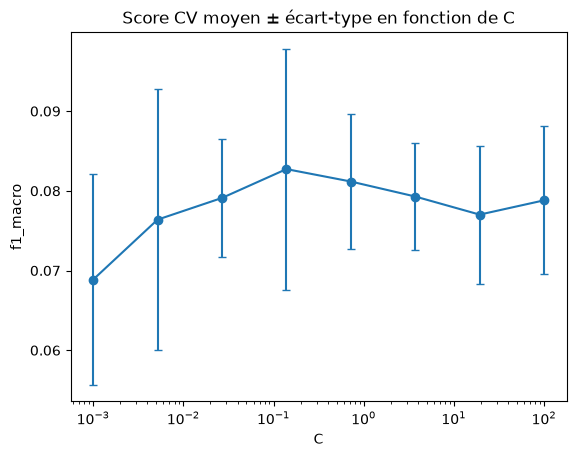

C = 0.1389 (moyenne 0.083 ± 0.015)


In [64]:
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from tqdm.auto import tqdm


C_values = np.logspace(-3, 2, 8)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True)

mean = []
std = []
for c in tqdm(C_values, desc="C"):
    pipe = Pipeline([("scale", StandardScaler()), ("classifier", LogisticRegression(C=c, max_iter=2000, class_weight="balanced")),])
    scores = cross_val_score(pipe, X_train, y_train, groups=g_train, cv=cv,scoring="f1_macro")
    mean.append(scores.mean())
    std.append(scores.std())
    tqdm.write(f"C={c:.4g} -> {scores.mean():.3f} ± {scores.std():.3f}")

plt.figure()
plt.title("Score CV moyen ± écart-type en fonction de C")
plt.errorbar(C_values, mean, yerr=std, marker="o", capsize=3)
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("f1_macro")
plt.show()

i_best = np.argmax(mean)
C_best = C_values[i_best]
print(f"C = {C_best:.4g} (moyenne {mean[i_best]:.3f} ± {std[i_best]:.3f})")

In [66]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

model_selectionne = Pipeline([('scale', StandardScaler()), ('classifier', LogisticRegression(C=C_best, max_iter =2000,class_weight="balanced"))])

model_selectionne.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](19,)","['Alternative','Black','Death',...,'Progressive','Speed','Thrash']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,768
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [51]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score

modeles = {
    "baseline (majoritaire)": base,
    "régression logistique": model_selectionne,
}

for nom, m in modeles.items():
    y_p = m.predict(X_val)
    y_proba = m.predict_proba(X_val)[:,1]
    print(f"{nom:25s} acc={accuracy_score(y_val, y_p):.3f}  "
          f"bal_acc={balanced_accuracy_score(y_val, y_p):.3f}  "
          f"f1={f1_score(y_val, y_p, average='macro'):.3f} ")

baseline (majoritaire)    acc=0.282  bal_acc=0.077  f1=0.034 
régression logistique     acc=0.108  bal_acc=0.075  f1=0.042 


C:\Users\LOZAY\OneDrive\Documents\pao\metal-mining\.pao\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


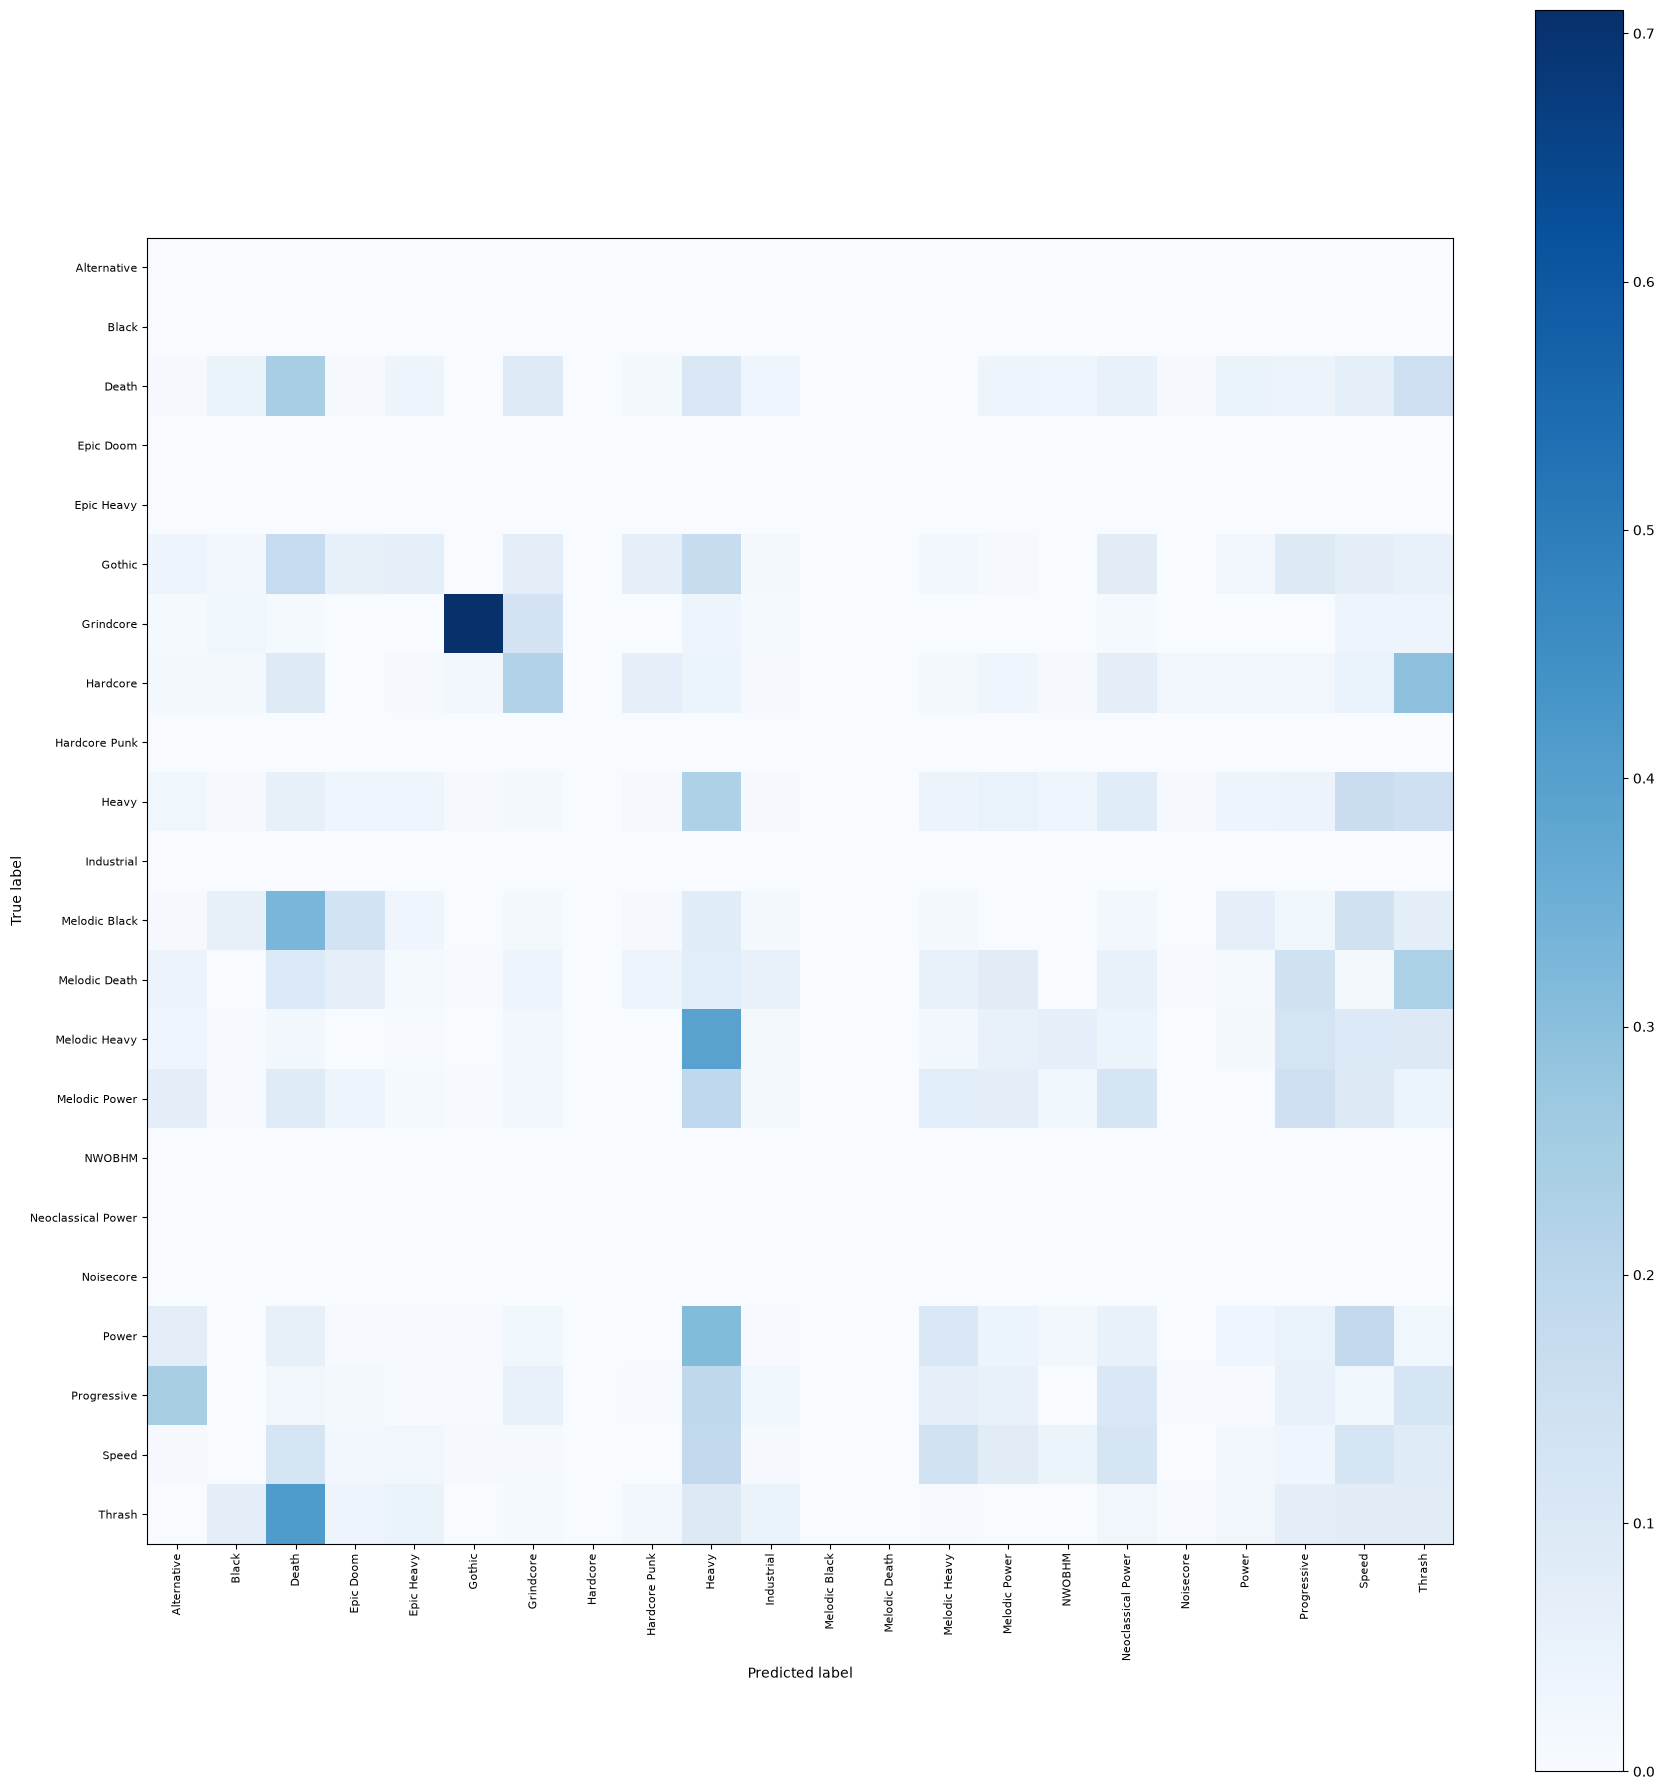

In [52]:
from sklearn.metrics import ConfusionMatrixDisplay
y_pred_valid = model_selectionne.predict(X_val)
fig, ax = plt.subplots(figsize=(18, 18))
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred_valid,
    normalize="true",
    include_values=False,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
    colorbar=True,
)
ax.tick_params(axis="both", labelsize=8)
plt.tight_layout()
plt.show()

Après visualisation des predictions dans la matrice de confusion. J'ai verifié si la proportion des genres était la même dans le train et le validation et il se trouve que pas du tout à cause du regroupement par groupes. On va donc essayer de faire sans stratifier par groupes

In [53]:
from sklearn.model_selection import train_test_split

X_dev, X_test, y_dev, y_test = train_test_split(
    X_vals, y, test_size=0.2, stratify=y
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev)

In [54]:
# 3. Proportions comparables
props = pd.DataFrame({
    "train_%": pd.Series(y_train).value_counts(normalize=True) * 100,
    "val_%":   pd.Series(y_valid).value_counts(normalize=True) * 100,
    "test_%":  pd.Series(y_test).value_counts(normalize=True) * 100,
}).fillna(0).round(1)
print(props)

                    train_%  val_%  test_%
Alternative             1.1    1.1     1.1
Black                   2.5    2.4     2.5
Death                   6.9    6.9     6.9
Doom                    1.5    1.5     1.5
Epic Doom               1.1    1.1     1.1
Epic Heavy              1.2    1.2     1.2
Gothic                  3.9    3.9     3.9
Grindcore               6.6    6.6     6.5
Hardcore                1.1    1.1     1.1
Hardcore Punk           2.1    2.1     2.1
Heavy                  29.2   29.2    29.2
Industrial              1.2    1.2     1.2
Melodic Black           1.1    1.1     1.1
Melodic Death           2.7    2.7     2.7
Melodic Heavy           2.6    2.6     2.6
Melodic Power           2.8    2.8     2.8
NWOBHM                  1.9    1.9     1.9
Neoclassical Power      1.6    1.6     1.6
Noisecore               1.1    1.2     1.2
Power                   5.5    5.5     5.5
Progressive             5.3    5.3     5.3
Sludge                  1.5    1.4     1.5
Speed      

C: 100%|██████████| 8/8 [07:39<00:00, 57.45s/it]


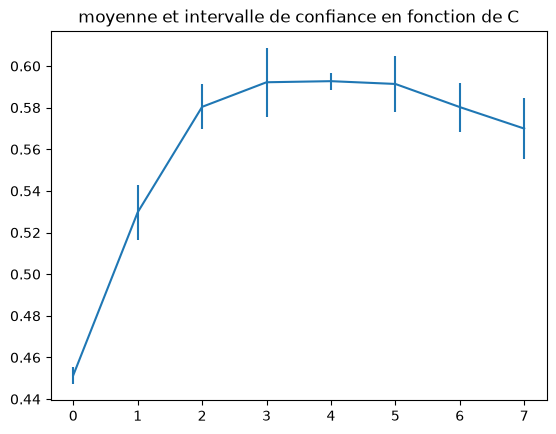

C = 0.7197 (moyenne 0.593 ± 0.004)


In [55]:
from sklearn.model_selection import StratifiedKFold
C_values = np.logspace(-3,2,8)
cv = StratifiedKFold(n_splits=5, shuffle = True)

mean = []
std = []
for c in tqdm(C_values, desc="C"):
    pipe = Pipeline([('scale', StandardScaler()), ('classifier', LogisticRegression(C=c, max_iter= 2000,class_weight="balanced"))])
    pipe.fit(X_train, y_train)
    score = cross_val_score(pipe, X_train, y_train, scoring='f1_macro', cv=cv)
    mean.append(score.mean())
    std.append(score.std())

plt.figure()
plt.title("moyenne et intervalle de confiance en fonction de C")
plt.errorbar(range(8), mean, yerr=std)
plt.show()

i_best = np.argmax(mean)
C_best = C_values[i_best]
print(f"C = {C_best:.4g} (moyenne {mean[i_best]:.3f} ± {std[i_best]:.3f})")

In [56]:
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

model_selectionne = Pipeline([('scale', StandardScaler()), ('classifier', LogisticRegression(C=C_best, max_iter =2000,class_weight="balanced"))])

model_selectionne.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](24,)","['Alternative','Black','Death',...,'Sludge','Speed','Thrash']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,768
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [57]:
modeles = {
    "baseline (majoritaire)": base,
    "régression logistique": model_selectionne,
}

for nom, m in modeles.items():
    y_p = m.predict(X_valid)
    y_proba = m.predict_proba(X_valid)[:,1]
    print(f"{nom:25s} acc={accuracy_score(y_valid, y_p):.3f}  "
          f"bal_acc={balanced_accuracy_score(y_valid, y_p):.3f}  "
          f"f1={f1_score(y_valid, y_p, average='macro'):.3f} ")

baseline (majoritaire)    acc=0.292  bal_acc=0.042  f1=0.019 
régression logistique     acc=0.585  bal_acc=0.621  f1=0.591 


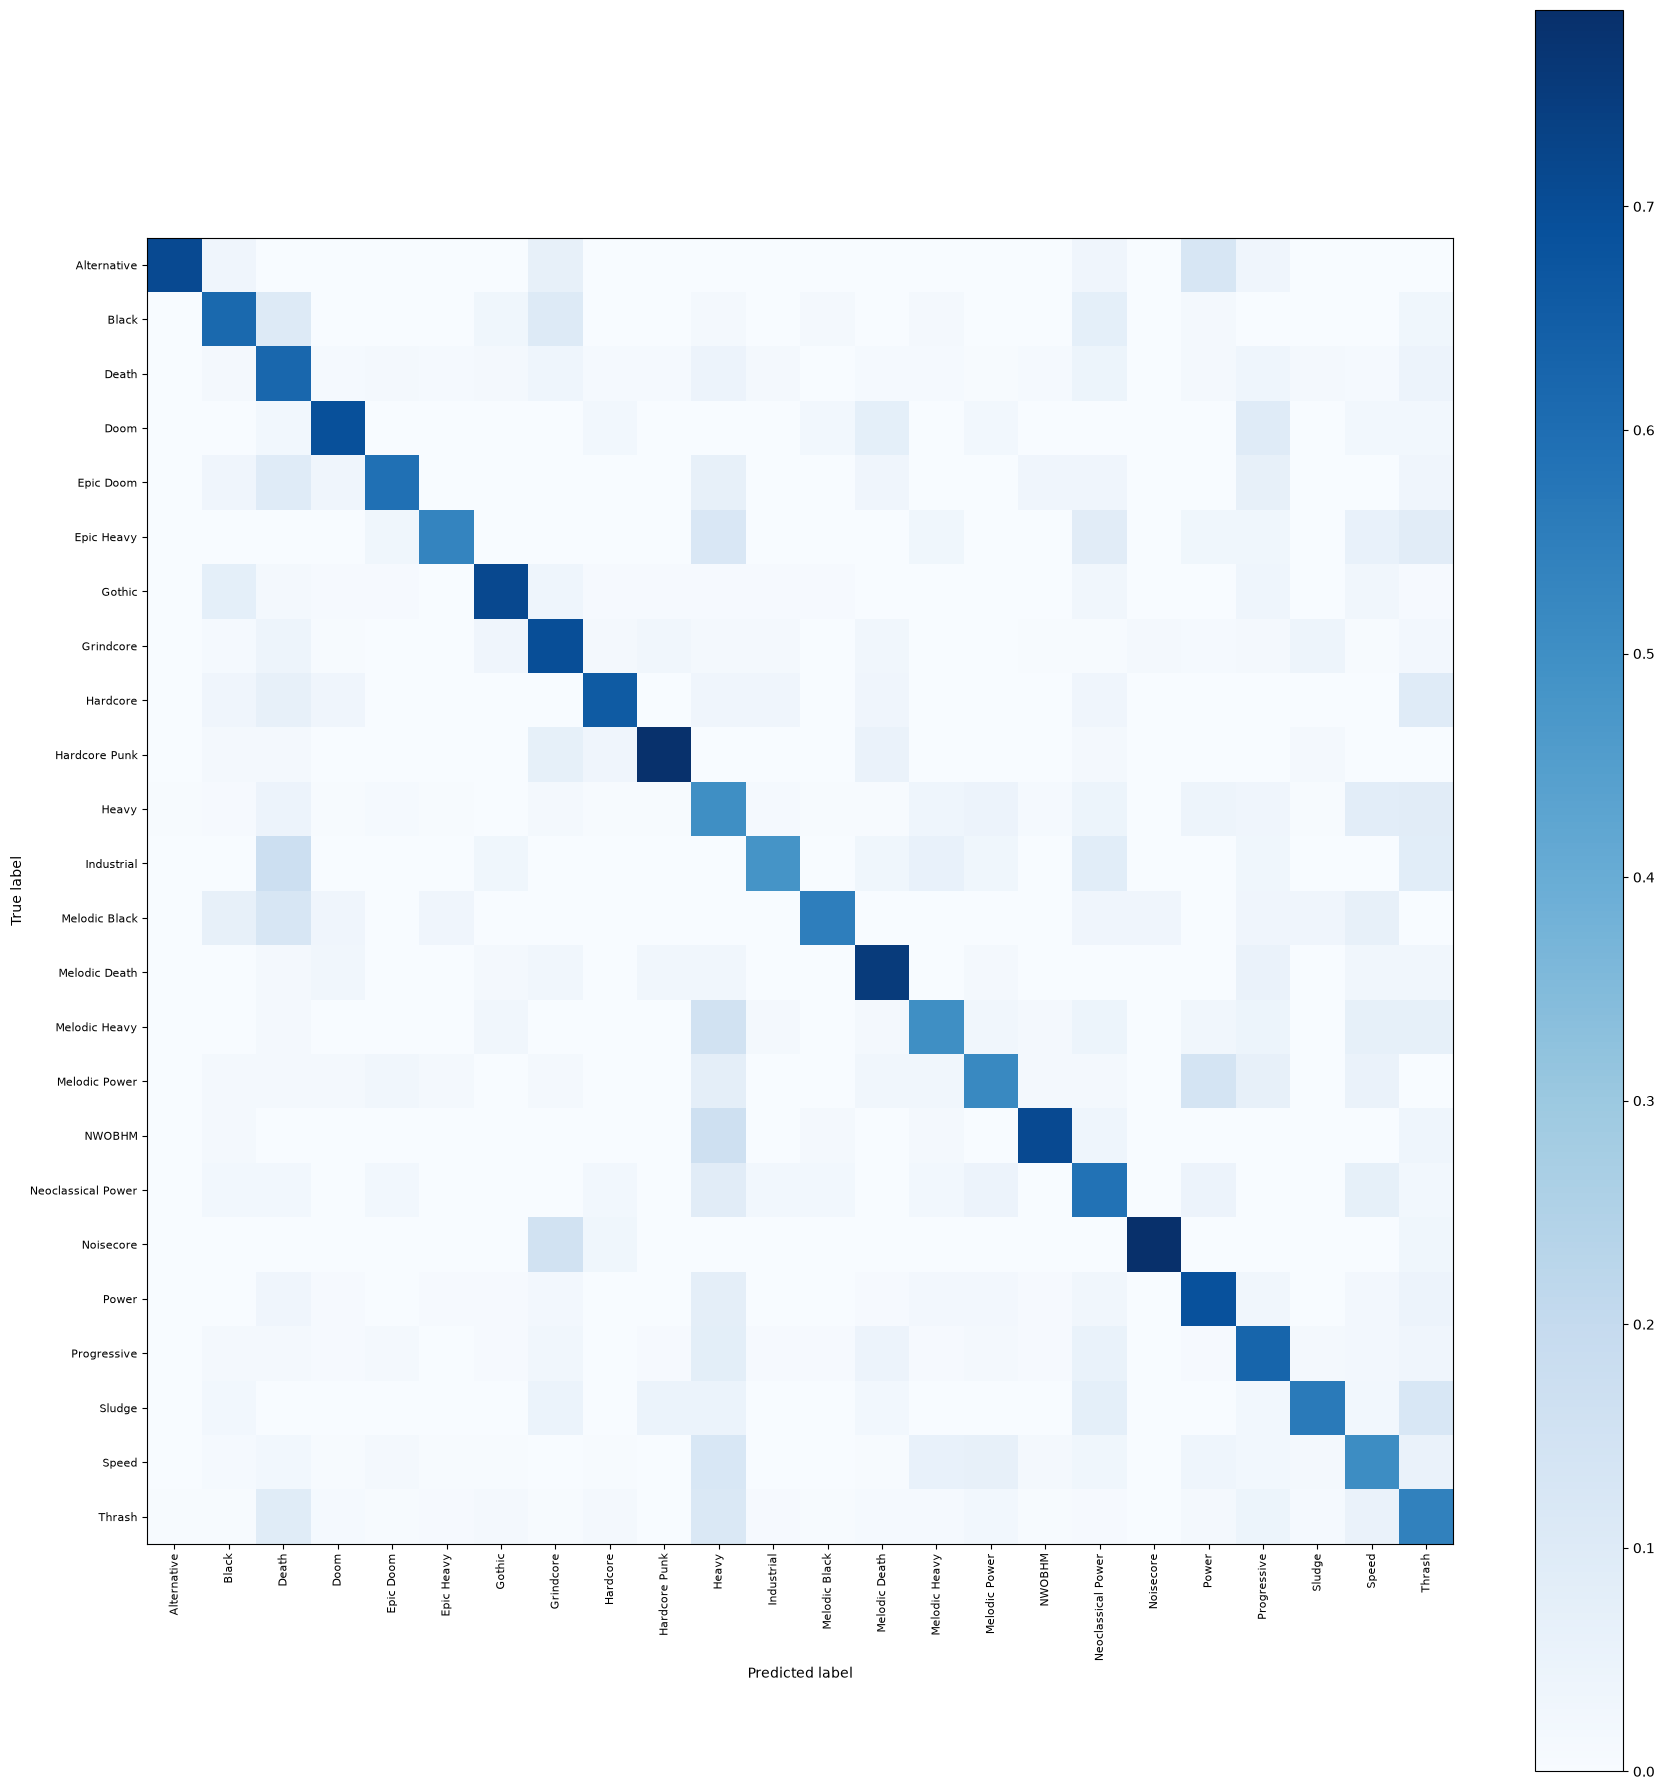

In [58]:
y_pred_valid = model_selectionne.predict(X_valid)
fig, ax = plt.subplots(figsize=(18, 18))
ConfusionMatrixDisplay.from_predictions(
    y_valid, y_pred_valid,
    normalize="true",
    include_values=False,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
    colorbar=True,
)
ax.tick_params(axis="both", labelsize=8)
plt.tight_layout()
plt.show()